# Correlation đúng thời điểm input của mô hình: mưa quá khứ + mưa dự báo

**Lấy t là thời điểm mực nước cần dự đoán ở horizon +24h. Input được đưa vào tại s = t−24h.**

| Đại lượng | Khoảng thời gian | Nguồn |
|---|---|---|
| Mưa quan trắc 24h tại input | **(t−48h, t−24h] = (s−24h, s]** | `rain_<id>_sum_24h` |
| Mưa dự báo cho 24h tiếp theo | **(t−24h, t] = (s, s+24h]** | Tổng 4 khoảng forecast, lấy tại **s** |
| Mức tăng nước cần dự đoán | **H(t) − H(t−24h)** | Nhãn +24h trừ nước tại input |
| Mực nước tuyệt đối | **H(t)** | Nhãn +24h; bảng phụ để đối chiếu |

Không lấy mưa quan trắc `(t−24h,t]` hoặc bản forecast tại t làm input: chúng chưa có tại s. Không lấy forecast mới hơn để sửa lại dự báo quá khứ.

Tính Pearson/Spearman cho (1) mưa quan trắc, (2) mưa dự báo, (3) **tổng mưa quan trắc 24h + dự báo 24h**. Đại lượng (3) là phép gộp để phân tích, **không phải cột input đang có trong dataset**. Mô hình hiện nhận riêng từng feature và chuỗi 96 bước; correlation này xem các predictor tại bước input cuối s, không đo toàn bộ khả năng của LSTM.

Xem riêng **all = hợp các anchor train/val/test**, và **train**; có bảng validation/test kiểm tra độ ổn định. Ưu tiên +24h theo câu hỏi; thêm +12h với nhãn tại s+12h và forecast 0–12h. Không train hoặc sửa dataset/model.


In [1]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/ai").is_dir())
DATASET = ROOT / "train_data/da_vien_1h_2026-10-15_rain_pool_o24"
SNAPSHOT = ROOT / "reports/rain_regions_h12_h24_20261019"
SEQUENCE_LENGTH = 96
MIN_COVERAGE = .90
MIN_PAIRS = 200
MODEL_B = {"750062", "750007"}
DIRECTIONS = ["Bắc", "Đông", "Nam", "Tây"]
FORECAST_COLS = [f"weather_forecast_rain_{a}_{b}h" for a, b in [(0,3),(3,6),(6,12),(12,24)]]
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

def read_frame(path):
    frame = pd.read_csv(path)
    frame.index = pd.DatetimeIndex(pd.to_datetime(frame.pop("timestamp_utc"), utc=True), name="input_time_s")
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert frame.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
    return frame

def show():
    buffer = BytesIO()
    plt.gcf().savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close()

spec = json.loads((DATASET / "manifest.json").read_text())
hourly = read_frame(DATASET / "hourly.csv")
provenance = pd.read_csv(DATASET / "weather_provenance.csv.gz")
provenance.index = pd.DatetimeIndex(pd.to_datetime(provenance.pop("timestamp_utc"), utc=True))
provenance["initialized_at"] = pd.to_datetime(provenance.initialized_at, utc=True)
assert provenance.index.is_unique
print("Chính sách forecast:", spec["availability_policy"])
print("Forecast hiện tại là một chuỗi cho một ô lưới chung, không có forecast riêng cho 55 trạm.")
print("Ô lưới của dataset nguồn: latitude=16.274164, longitude=107.26496.")
print("Thời điểm công bố lịch sử dùng giả định init+6h; nguồn có hindcast. Không coi đây là backtest vận hành đã xác minh hoàn toàn.")

Chính sách forecast: run init + assumed 6h <= anchor; use older complete run max age24h
Forecast hiện tại là một chuỗi cho một ô lưới chung, không có forecast riêng cho 55 trạm.
Ô lưới của dataset nguồn: latitude=16.274164, longitude=107.26496.
Thời điểm công bố lịch sử dùng giả định init+6h; nguồn có hindcast. Không coi đây là backtest vận hành đã xác minh hoàn toàn.


## 1. Dùng đúng anchor và predictor của dataset
Mỗi split bỏ 95 giờ đầu giống sequence 96 của training, yêu cầu nước hiện tại và đủ 24 nhãn giờ như cohort O5/O24. Không bỏ mẫu vì mưa thiếu. All là hợp ba split, không thêm các giờ purge vào mẫu phân tích.

Với 6 trạm trong pool, dùng **nguyên cột sum_24h** của dataset. Các trạm còn lại được dựng cùng quy tắc builder pool từ snapshot: tổng giờ, rolling đủ 24 giờ, invalid/âm thành NaN, không tự đổi sang quy tắc lọc 6/6 số đo của notebook sự kiện. Không chuẩn hóa hoặc điền 0 trước tính corr; bảng n/coverage ghi rõ phần dữ liệu thực có.


In [2]:
raw = pd.read_csv(SNAPSHOT / "hourly_rain.csv.gz", dtype={"station_id": str})
raw["station_id"] = raw.station_id.str.lstrip("0")
raw["timestamp_utc"] = pd.to_datetime(raw.timestamp_utc, utc=True)
assert not raw.duplicated(["station_id", "timestamp_utc"]).any()
invalid = raw.n_valid.le(0) | raw.n_invalid.gt(0) | raw.rain_mm.lt(0) | ~np.isfinite(raw.rain_mm)
raw.loc[invalid, "rain_mm"] = np.nan
rain_hourly = raw.pivot(index="timestamp_utc", columns="station_id", values="rain_mm").sort_index()
grid = pd.date_range(rain_hourly.index.min(), rain_hourly.index.max(), freq="1h")
rain_past24 = rain_hourly.reindex(grid).rolling(24, min_periods=24).sum().reindex(hourly.index)
for sid in spec["rain_station_ids"]:
    rain_past24[sid] = hourly[f"rain_{sid}_sum_24h"]

frames, past, cohorts = {}, {}, []
for split in ["train", "val", "test"]:
    frame = read_frame(DATASET / f"{split}.csv")
    eligible = frame[spec["target_columns"]].notna().all(axis=1) & frame.water_level_depth.notna()
    eligible &= np.arange(len(frame)) >= SEQUENCE_LENGTH - 1
    frame = frame.loc[eligible].copy()
    frames[split] = frame
    station_frame = rain_past24.reindex(frame.index).copy()
    for sid in spec["rain_station_ids"]:
        station_frame[sid] = frame[f"rain_{sid}_sum_24h"]
    past[split] = station_frame
    cohorts.append(dict(scope=split, anchors=len(frame), first_input_s=str(frame.index.min()),
        last_input_s=str(frame.index.max()), last_target_t=str(frame.index.max() + pd.Timedelta(hours=24))))
frames["all"] = pd.concat([frames[s] for s in ["train", "val", "test"]]).sort_index()
past["all"] = pd.concat([past[s] for s in ["train", "val", "test"]]).sort_index()
assert frames['all'].index.is_unique
scopes = ["all", "train", "val", "test"]
display(pd.DataFrame(cohorts))

for scope in scopes:
    frame = frames[scope]
    runs = provenance.reindex(frame.index)
    assert runs.initialized_at.notna().all()
    assert (runs.initialized_at + pd.Timedelta(hours=6) <= frame.index).all()
    assert frame.weather_forecast_age_hours.between(6,24).all()
    for h in [12,24]:
        target = f"target_water_level_plus_{h*60}m"
        observed = hourly.water_level_depth.reindex(frame.index + pd.Timedelta(hours=h)).to_numpy()
        np.testing.assert_allclose(frame[target], observed, rtol=0, atol=1e-8)

sample = frames["train"].iloc[len(frames["train"]) // 2]
s = sample.name
display(pd.DataFrame([dict(input_s=s, target_t=s + pd.Timedelta(hours=24),
    rain_observed_from=s - pd.Timedelta(hours=24), rain_observed_to=s,
    forecast_from=s, forecast_to=s + pd.Timedelta(hours=24),
    forecast_initialized_at=provenance.loc[s, "initialized_at"],
    hong_thai_observed24=sample.rain_750062_sum_24h,
    forecast24=sample[FORECAST_COLS].sum(min_count=4),
    level_at_input=sample.water_level_depth,
    target_level=sample.target_water_level_plus_1440m)]))
print("Bảng ví dụ dùng UTC; cộng 7 giờ để đọc theo giờ Việt Nam.")

Bảng ví dụ dùng UTC; cộng 7 giờ để đọc theo giờ Việt Nam.


,scope,anchors,first_input_s,last_input_s,last_target_t
0,train,6095,2025-11-18 18:00:00+00:00,2026-07-30 16:00:00+00:00,2026-07-31 16:00:00+00:00
1,val,985,2026-08-04 16:00:00+00:00,2026-09-14 16:00:00+00:00,2026-09-15 16:00:00+00:00
2,test,592,2026-09-19 16:00:00+00:00,2026-10-14 07:00:00+00:00,2026-10-15 07:00:00+00:00


,input_s,target_t,rain_observed_from,rain_observed_to,forecast_from,forecast_to,forecast_initialized_at,hong_thai_observed24,forecast24,level_at_input,target_level
0,2026-03-25 17:00:00+00:00,2026-03-26 17:00:00+00:00,2026-03-24 17:00:00+00:00,2026-03-25 17:00:00+00:00,2026-03-25 17:00:00+00:00,2026-03-26 17:00:00+00:00,2026-03-25 06:00:00+00:00,0.0,0.1,468.483333,503.733333


In [3]:
catalog = pd.read_csv(SNAPSHOT / "station_catalog.csv", dtype={"id": str}).rename(columns={"id": "station_id"})
catalog.station_id = catalog.station_id.str.lstrip("0")
water_meta = pd.read_csv(ROOT / "data/water_level_stations.csv.gz", dtype={"code": str})
water_station = water_meta.loc[water_meta.code.str.lstrip("0").eq("74647403")].iloc[0]
lon0, lat0 = json.loads(water_station.geom)["coordinates"][:2]
lat = np.radians(catalog.latitude.to_numpy(float))
dlon = np.radians(catalog.longitude.to_numpy(float) - lon0)
y = np.sin(dlon) * np.cos(lat)
x = np.cos(np.radians(lat0)) * np.sin(lat) - np.sin(np.radians(lat0)) * np.cos(lat) * np.cos(dlon)
catalog["bearing_deg"] = (np.degrees(np.arctan2(y,x)) + 360) % 360
catalog["direction"] = catalog.bearing_deg.map(lambda b: DIRECTIONS[int((b+45)//90)%4])
catalog["model_B"] = catalog.station_id.isin(MODEL_B)
catalog = catalog.set_index("station_id", drop=False)
assert set(past['all']) == set(catalog.index)

## 2. Correlation mưa quá khứ, forecast và tổng hai phần
Đích chính là **ΔH24 = H(t)−H(t−24h)**. Bảng có thêm `level_r` với H(t), nhưng không dùng nó để xếp hạng vì mực nước tuyệt đối dễ phản ánh mùa và trạng thái nền.

Trong mỗi trạm/horizon, ba predictor **past / forecast / past+forecast** được tính trên đúng cùng tập cặp hợp lệ. Riêng forecast dùng một ô lưới chung; khác biệt nhỏ ở r forecast giữa hàng trạm có thể chỉ do các trạm thiếu dữ liệu ở các giờ khác nhau. Phần 3 sẽ đưa tất cả ứng viên đủ phủ về **cùng một cohort** để xếp hạng công bằng.


In [4]:
def corr(x,y,method="pearson"):
    if len(x) < 3 or x.nunique() < 2 or y.nunique() < 2:
        return np.nan
    return x.corr(y, method=method)

records = []
for scope in scopes:
    frame = frames[scope]
    for h in [12,24]:
        cols = FORECAST_COLS[:3] if h == 12 else FORECAST_COLS
        forecast = frame[cols].sum(axis=1, min_count=len(cols))
        flags = frame[[c + "_missing" for c in cols]].eq(0).all(axis=1)
        forecast = forecast.where(flags)
        target_level = frame[f"target_water_level_plus_{h*60}m"]
        target_delta = target_level - frame.water_level_depth
        for sid in past[scope]:
            observed = past[scope][sid]
            valid = observed.notna() & forecast.notna() & target_delta.notna()
            n = int(valid.sum())
            for name, predictor in [("observed_past24", observed), (f"forecast_next{h}", forecast),
                                    (f"observed24_plus_forecast{h}", observed + forecast)]:
                records.append(dict(scope=scope, station_id=sid, horizon=h, predictor=name,
                    n=n, coverage=n / len(frame), pearson=corr(predictor[valid], target_delta[valid]),
                    spearman=corr(predictor[valid], target_delta[valid], "spearman"),
                    level_r=corr(predictor[valid], target_level[valid])))
results = pd.DataFrame(records).merge(catalog[["name", "direction", "model_B"]], left_on="station_id", right_index=True)
for scope in ["all", "train"]:
    main = results.loc[results.scope.eq(scope) & results.horizon.eq(24)]
    table = main.pivot(index=["station_id", "name", "direction", "model_B"], columns="predictor", values="pearson")
    counts = main.drop_duplicates("station_id").set_index("station_id")[["n", "coverage"]]
    table = table.join(counts, on="station_id").sort_values("observed24_plus_forecast24", ascending=False)
    display(Markdown(f"### {scope}: Pearson với ΔH24 — từng trạm dùng cặp hợp lệ riêng"))
    display(table.round(3))

### all: Pearson với ΔH24 — từng trạm dùng cặp hợp lệ riêng

,,,,forecast_next24,observed24_plus_forecast24,observed_past24,n,coverage
station_id,name,direction,model_B,,,,,
750025,Thị trấn Phong Điền (Phong Điền),Tây,False,0.138,0.080,0.009,7596,0.990
750040,Hương Chữ (Hương Trà),Tây,False,0.139,0.059,-0.037,7462,0.973
750013,Lưu vực Thủy điện Thượng Nhật (Phú Lộc),Nam,False,0.137,0.057,-0.180,6659,0.868
750002,Hồ Mỹ Xuyên (Phong Điền),Tây,False,0.138,0.055,-0.034,7672,1.000
750045,Đan Điền (Đập Cửa Lác),Bắc,False,0.138,0.050,-0.062,7672,1.000
750023,Quảng Phú (Quảng Điền),Tây,False,0.139,0.049,-0.054,7558,0.985
681524,Hồ Thọ Sơn (Hương Trà),Tây,False,0.138,0.040,-0.044,7672,1.000
750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,False,0.138,0.039,-0.061,7672,1.000
750064,Điền Hương (Phong Điền),Bắc,False,0.141,0.032,-0.086,7490,0.976


### train: Pearson với ΔH24 — từng trạm dùng cặp hợp lệ riêng

,,,,forecast_next24,observed24_plus_forecast24,observed_past24,n,coverage
station_id,name,direction,model_B,,,,,
750025,Thị trấn Phong Điền (Phong Điền),Tây,False,0.080,0.019,-0.077,6095,1.000
750002,Hồ Mỹ Xuyên (Phong Điền),Tây,False,0.080,0.018,-0.075,6095,1.000
750059,Cảng Thuận An,Bắc,False,0.080,0.014,-0.102,6095,1.000
750027,Thủy Thanh (Hương Thủy),Đông,False,0.085,0.012,-0.089,5548,0.910
750023,Quảng Phú (Quảng Điền),Tây,False,0.080,0.011,-0.112,5981,0.981
750003,Thị trấn A Lưới (A Lưới),Tây,False,0.080,0.003,-0.079,6054,0.993
750063,Phú Sơn (Hương Thủy),Nam,False,0.079,0.002,-0.071,5992,0.983
750064,Điền Hương (Phong Điền),Bắc,False,0.082,0.002,-0.113,5983,0.982
750045,Đan Điền (Đập Cửa Lác),Bắc,False,0.080,-0.000,-0.128,6095,1.000


## 3. Xếp hạng cùng cohort và hình so sánh
Ứng viên đủ điều kiện có ≥90% coverage và ≥200 cặp trong scope tương ứng. Xếp hạng Pearson **past+forecast** và hiển thị riêng Pearson past, forecast để nhận ra phần nào mang thông tin. Cohort chung là giao các giờ hợp lệ của ứng viên; mọi hàng dùng cùng đích và cùng forecast. Cũng hiển thị hạng theo **past-only** để tránh hiểu tổng hai phần là cách gộp tối ưu; cộng trực tiếp là một giả thuyết chẩn đoán, không phải kết quả fit mô hình.

Xếp hạng all có dùng test nên là khám phá; trạm dùng để kiểm tra các split ở phần 4 được chọn **chỉ trên train**.


all: 52 ứng viên; 4,519/7,672 anchor chung (58.9%)
train: 51 ứng viên; 3,879/6,095 anchor chung (63.6%)


,station_id,name,direction,model_B,n,past_r,forecast_r,combined_r,combined_spearman,past_rank,combined_rank
40,750045,Đan Điền (Đập Cửa Lác),Bắc,False,4519,-0.032,0.153,0.083,0.003,2.0,1.0
27,750025,Thị trấn Phong Điền (Phong Điền),Tây,False,4519,-0.009,0.153,0.078,0.023,1.0,2.0
13,750006,Hương Nguyên (A Lưới),Nam,False,4519,-0.087,0.153,0.076,0.001,13.0,3.0
37,750040,Hương Chữ (Hương Trà),Tây,False,4519,-0.058,0.153,0.064,0.020,6.0,4.0
33,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,False,4519,-0.091,0.153,0.058,0.014,14.0,5.0
25,750023,Quảng Phú (Quảng Điền),Tây,False,4519,-0.074,0.153,0.051,0.015,9.0,6.0
34,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,False,4519,-0.082,0.153,0.051,0.016,12.0,7.0
5,677851,TT Sịa (Quảng Điền),Bắc,False,4519,-0.096,0.153,0.045,0.013,15.0,8.0
7,681524,Hồ Thọ Sơn (Hương Trà),Tây,False,4519,-0.062,0.153,0.041,0.009,7.0,9.0
23,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đông,False,4519,-0.052,0.153,0.039,0.006,5.0,10.0


,station_id,name,direction,model_B,n,past_r,forecast_r,combined_r,combined_spearman,past_rank,combined_rank
47,750064,Điền Hương (Phong Điền),Bắc,False,3879,-0.038,0.019,-0.008,-0.028,1.0,1.0
24,750022,Đồn Biên phòng Cảng Chân Mây (Phú Lộc),Đông,False,3879,-0.049,0.019,-0.011,-0.025,4.0,2.0
46,750063,Phú Sơn (Hương Thủy),Nam,False,3879,-0.043,0.019,-0.012,-0.033,2.0,3.0
25,750023,Quảng Phú (Quảng Điền),Tây,False,3879,-0.059,0.019,-0.013,-0.030,7.0,4.0
27,750025,Thị trấn Phong Điền (Phong Điền),Tây,False,3879,-0.053,0.019,-0.014,-0.023,6.0,5.0
10,750002,Hồ Mỹ Xuyên (Phong Điền),Tây,False,3879,-0.050,0.019,-0.016,-0.024,5.0,6.0
9,750001,TT Phú Đa (Phú Vang),Đông,False,3879,-0.065,0.019,-0.018,-0.026,8.0,7.0
17,750010,Giang Hải (Phú Lộc),Đông,False,3879,-0.047,0.019,-0.019,-0.029,3.0,8.0
23,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đông,False,3879,-0.074,0.019,-0.023,-0.043,9.0,9.0
19,750012,"Đập, Thủy điện Thượng Nhật (Phú Lộc)",Nam,False,3879,-0.095,0.019,-0.027,-0.007,17.0,10.0


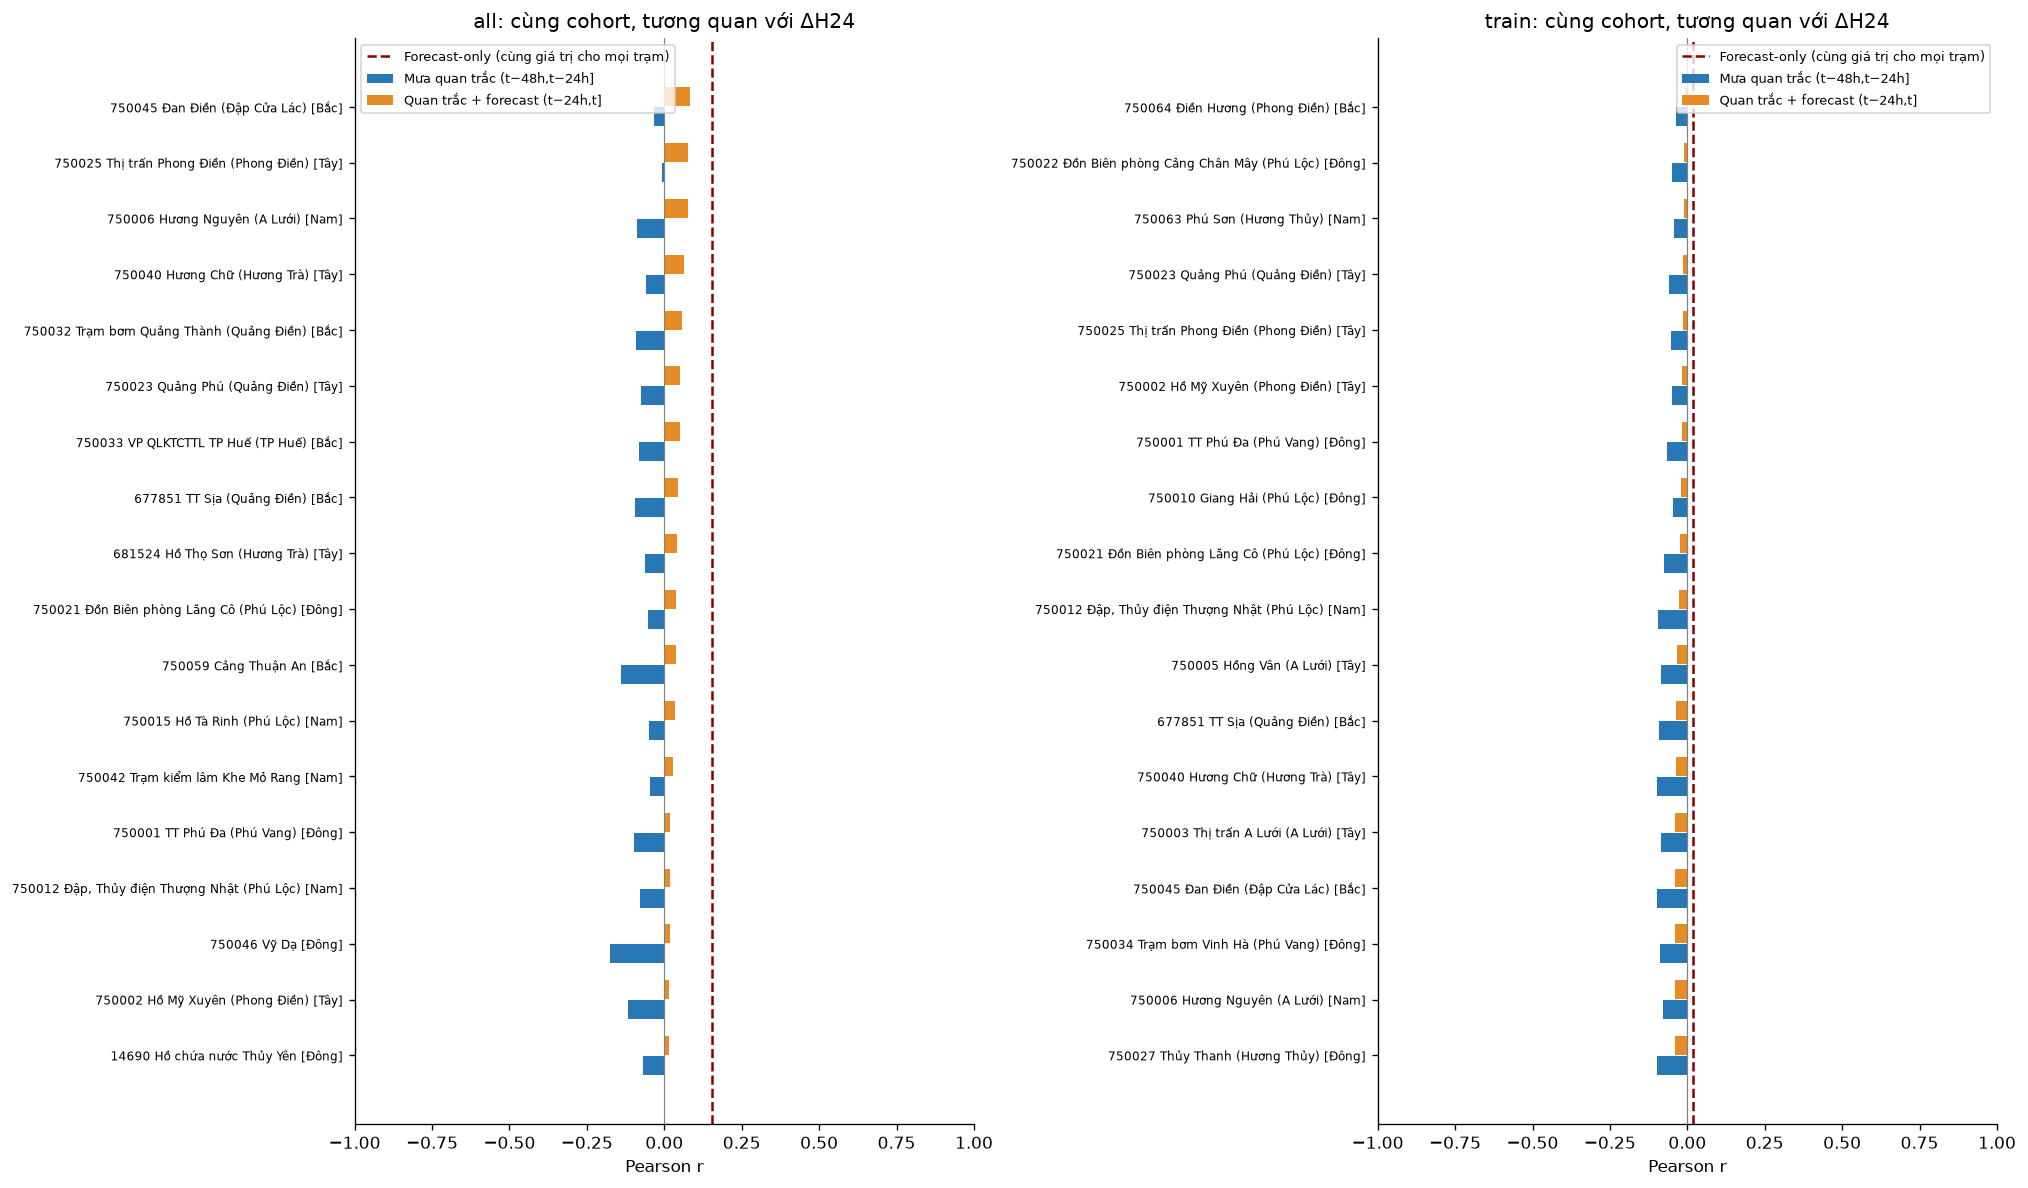

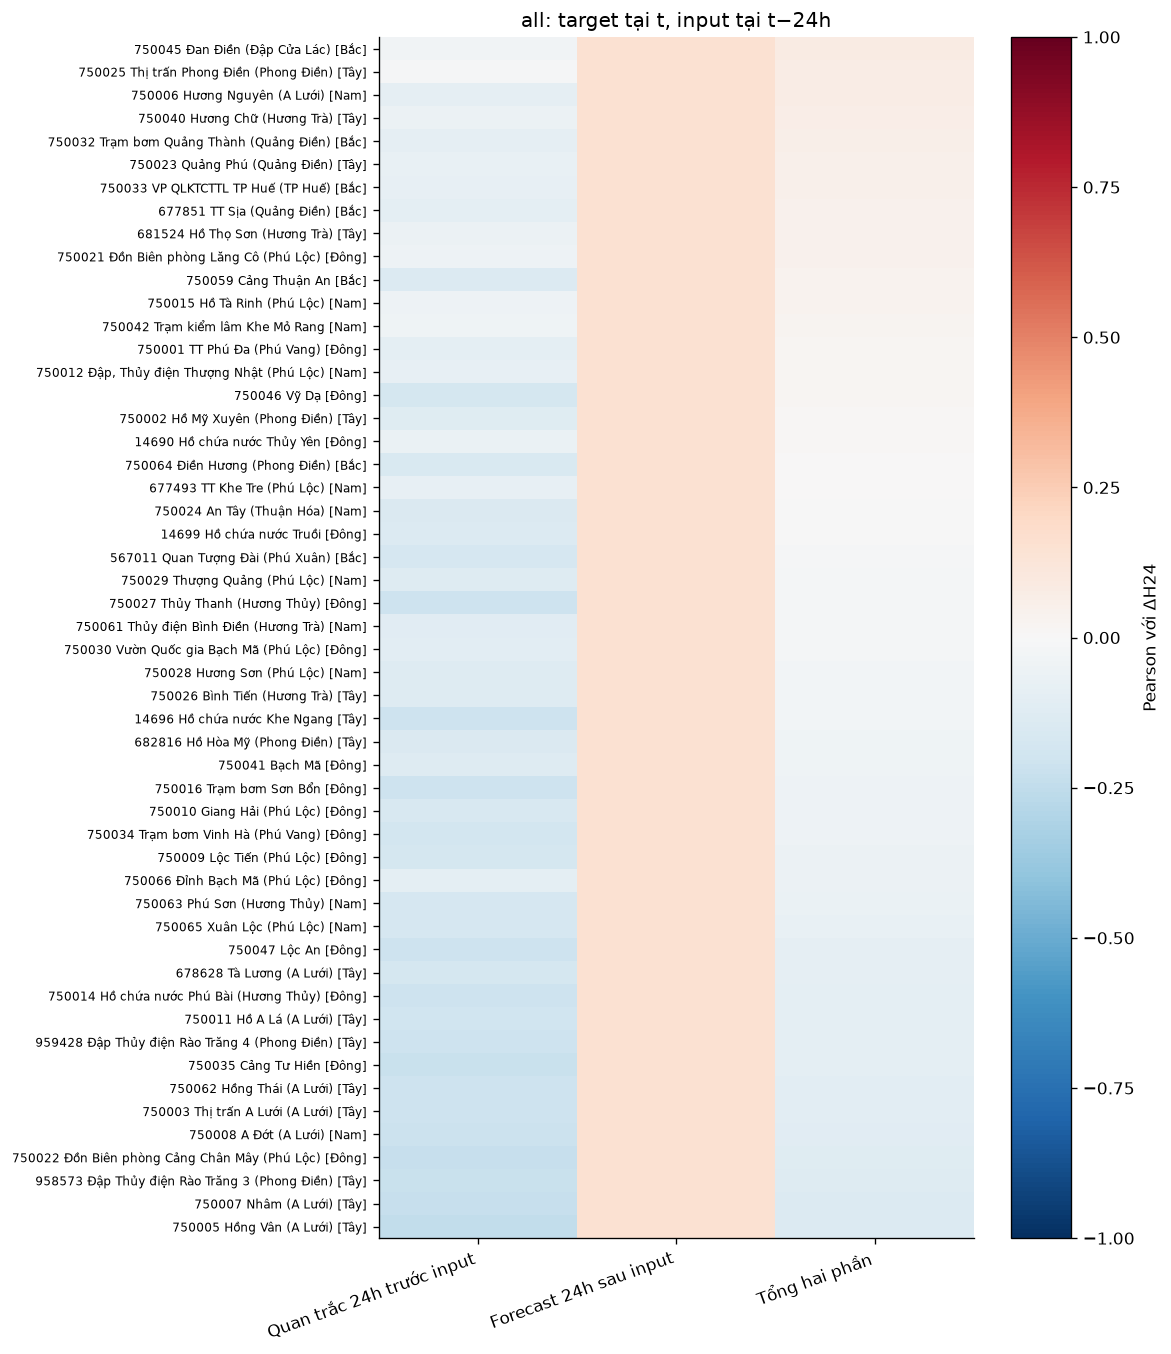

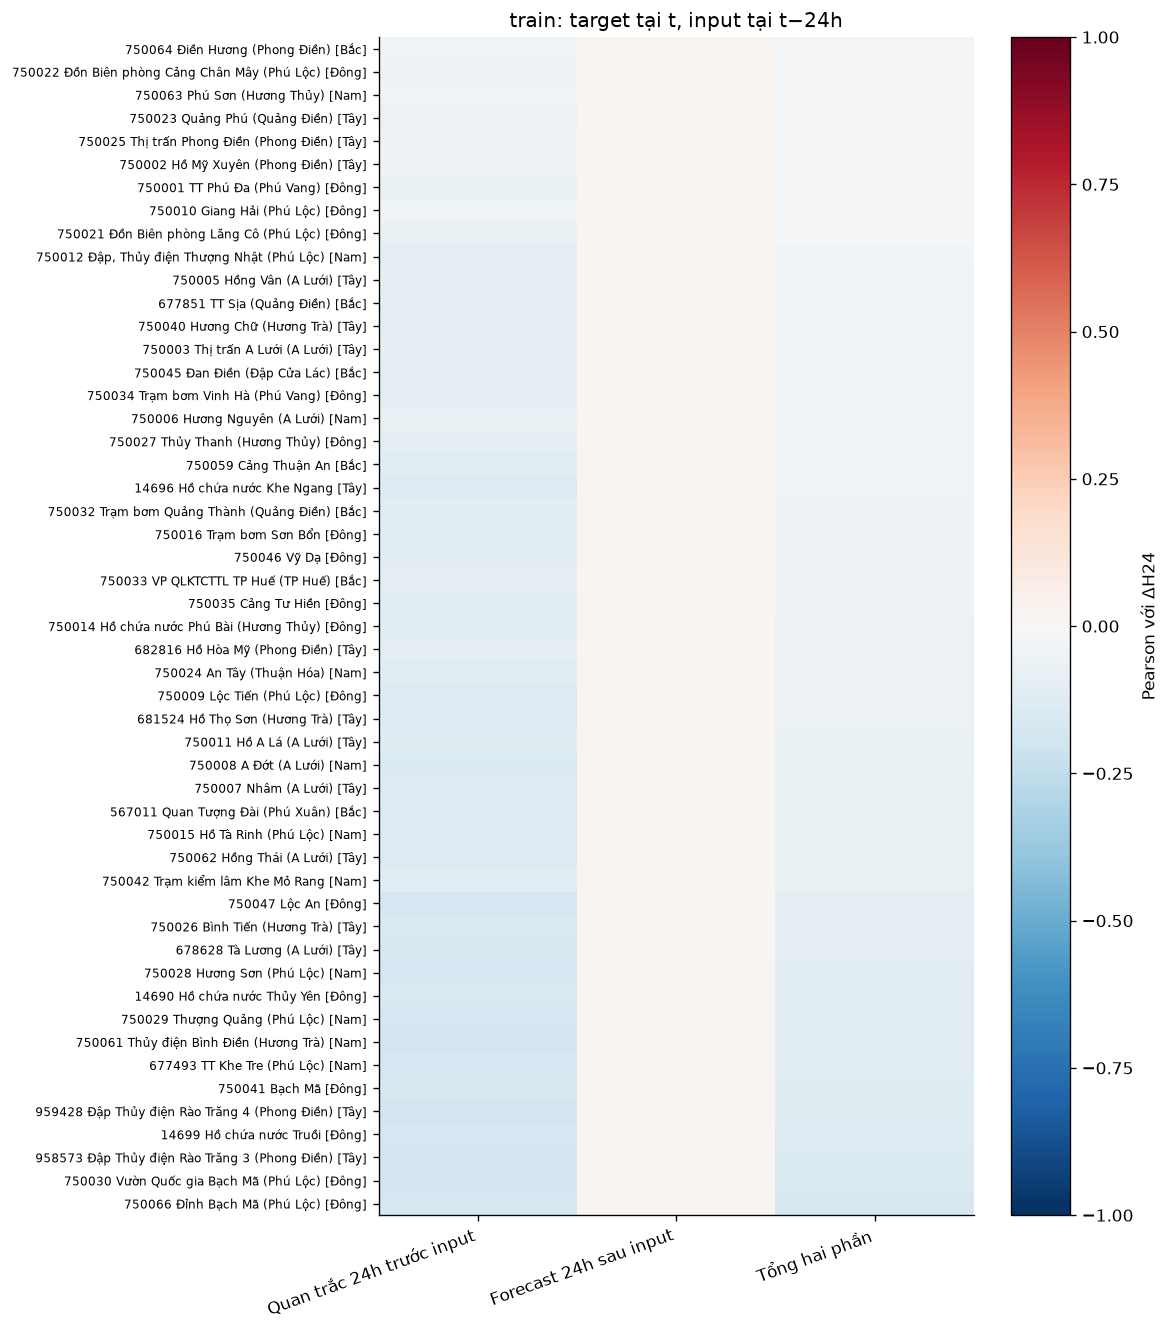

In [5]:
common_tables = {}
common_masks = {}
for scope in scopes:
    frame = frames[scope]
    candidate_info = results.loc[results.scope.eq(scope) & results.horizon.eq(24) & results.predictor.eq('observed_past24')]
    ids = candidate_info.loc[candidate_info.coverage.ge(MIN_COVERAGE) & candidate_info.n.ge(MIN_PAIRS), 'station_id'].tolist()
    forecast = frame[FORECAST_COLS].sum(axis=1, min_count=4)
    known_forecast = frame[[c + '_missing' for c in FORECAST_COLS]].eq(0).all(axis=1)
    common = past[scope][ids].notna().all(axis=1) & forecast.notna() & known_forecast if ids else pd.Series(False,index=frame.index)
    common_masks[scope] = common
    delta24 = frame.target_water_level_plus_1440m - frame.water_level_depth
    rows = []
    for sid in ids:
        observed = past[scope][sid]
        rows.append(dict(station_id=sid, name=catalog.loc[sid,'name'], direction=catalog.loc[sid,'direction'], model_B=sid in MODEL_B,
            n=int(common.sum()), past_r=corr(observed[common],delta24[common]),
            forecast_r=corr(forecast[common],delta24[common]),
            combined_r=corr((observed+forecast)[common],delta24[common]),
            combined_spearman=corr((observed+forecast)[common],delta24[common],'spearman')))
    table = pd.DataFrame(rows,columns=['station_id','name','direction','model_B','n','past_r','forecast_r','combined_r','combined_spearman'])
    table['past_rank'] = table.past_r.rank(ascending=False,method='min')
    table['combined_rank'] = table.combined_r.rank(ascending=False,method='min')
    common_tables[scope] = table.sort_values('combined_r',ascending=False)
    if scope in ['all','train']:
        print(f"{scope}: {len(ids)} ứng viên; {common.sum():,}/{len(frame):,} anchor chung ({common.mean():.1%})")
        display(common_tables[scope].round(3))

fig,axes = plt.subplots(1,2,figsize=(17,10))
for ax,scope in zip(axes,['all','train']):
    table = common_tables[scope].head(18).iloc[::-1]
    pos = np.arange(len(table))
    ax.barh(pos-.18,table.past_r,height=.34,label='Mưa quan trắc (t−48h,t−24h]',color='#2878b5')
    ax.barh(pos+.18,table.combined_r,height=.34,label='Quan trắc + forecast (t−24h,t]',color='#e58c27')
    ax.set_yticks(pos,[f"{r.station_id} {r['name']} [{r.direction}]{' [B]' if r.model_B else ''}" for _,r in table.iterrows()],fontsize=7)
    if len(table):
        ax.axvline(table.forecast_r.iloc[0],color='darkred',linestyle='--',label='Forecast-only (cùng giá trị cho mọi trạm)')
    ax.axvline(0,color='grey',linewidth=.7)
    ax.set(xlim=(-1,1),title=f'{scope}: cùng cohort, tương quan với ΔH24',xlabel='Pearson r')
    ax.legend(fontsize=8)
fig.tight_layout()
show()

for scope in ['all','train']:
    table=common_tables[scope]
    fig,ax=plt.subplots(figsize=(8,max(6,len(table)*.25)))
    image=ax.imshow(table[['past_r','forecast_r','combined_r']].to_numpy(float),aspect='auto',vmin=-1,vmax=1,cmap='RdBu_r')
    ax.set_yticks(range(len(table)),[f"{r.station_id} {r['name']} [{r.direction}]" for _,r in table.iterrows()],fontsize=7)
    ax.set_xticks([0,1,2],['Quan trắc 24h trước input','Forecast 24h sau input','Tổng hai phần'],rotation=20,ha='right')
    ax.set_title(f'{scope}: target tại t, input tại t−24h')
    fig.colorbar(image,ax=ax,label='Pearson với ΔH24')
    show()

## 4. Các feature forecast thực tế và kiểm tra ổn định
Forecast trong dataset gồm 4 khoảng rời nhau **0–3h, 3–6h, 6–12h, 12–24h sau s**. Tổng chúng là forecast 24h, không phải cộng các cửa sổ chồng lấn. Dưới đây tính riêng từng feature và tổng để so với ΔH12/ΔH24. Các khoảng 12–24h vẫn được hiển thị với ΔH12 vì đó là feature sẵn có tại s, nhưng không diễn giải là mưa nằm trước đích +12h.


Các trạm được theo dõi: 6 trạm pool hiện tại + top 6 chọn trên train.


,scope,horizon,feature,n,pearson,spearman
0,all,12,weather_forecast_rain_0_3h,7672,0.123,0.142
1,all,12,weather_forecast_rain_3_6h,7672,0.096,0.065
2,all,12,weather_forecast_rain_6_12h,7672,0.052,-0.109
3,all,12,weather_forecast_rain_12_24h,7672,0.133,0.042
4,all,12,forecast_total_24h,7672,0.131,0.020
5,all,24,weather_forecast_rain_0_3h,7672,0.033,-0.056
6,all,24,weather_forecast_rain_3_6h,7672,0.045,-0.036
7,all,24,weather_forecast_rain_6_12h,7672,0.053,-0.005
8,all,24,weather_forecast_rain_12_24h,7672,0.188,0.029
9,all,24,forecast_total_24h,7672,0.138,0.008


scope                                                                                             all  \
station_id name                                   direction horizon predictor                           
750002     Hồ Mỹ Xuyên (Phong Điền)               Tây       12      forecast_next12             0.097   
                                                                    observed24_plus_forecast12  0.010   
                                                                    observed_past24            -0.036   
                                                            24      forecast_next24             0.138   
                                                                    observed24_plus_forecast24  0.055   
                                                                    observed_past24            -0.034   
750007     Nhâm (A Lưới)                          Tây       12      forecast_next12             0.097   
                                                                    observed24_plus_forecast12 -0.041   
                                                                    observed_past24            -0.076   
                                                            24      forecast_next24             0.138   
                                                                    observed24_plus_forecast24 -0.080   
                                                                    observed_past24            -0.174   
750014     Hồ chứa nước Phú Bài (Hương Thủy)      Đông      12      forecast_next12             0.097   
                                                                    observed24_plus_forecast12 -0.057   
                                                                    observed_past24            -0.097   
                                                            24      forecast_next24             0.139   
                                                                    observed24_plus_forecast24 -0.069   
                                                                    observed_past24            -0.164   
750022     Đồn Biên phòng Cảng Chân Mây (Phú Lộc) Đông      12      forecast_next12             0.099   
                                                                    observed24_plus_forecast12 -0.041   
                                                                    observed_past24            -0.074   
                                                            24      forecast_next24             0.142   
                                                                    observed24_plus_forecast24 -0.069   
                                                                    observed_past24            -0.154   
750023     Quảng Phú (Quảng Điền)                 Tây       12      forecast_next12             0.098   
                                                                    observed24_plus_forecast12  0.011   
                                                                    observed_past24            -0.041   
                                                            24      forecast_next24             0.139   
                                                                    observed24_plus_forecast24  0.049   
                                                                    observed_past24            -0.054   
750025     Thị trấn Phong Điền (Phong Điền)       Tây       12      forecast_next12             0.097   
                                                                    observed24_plus_forecast12  0.028   
                                                                    observed_past24            -0.012   
                                                            24      forecast_next24             0.138   
                                                                    observed24_plus_forecast24  0.080   
                                                                    observed_past24             0.009   
750033    

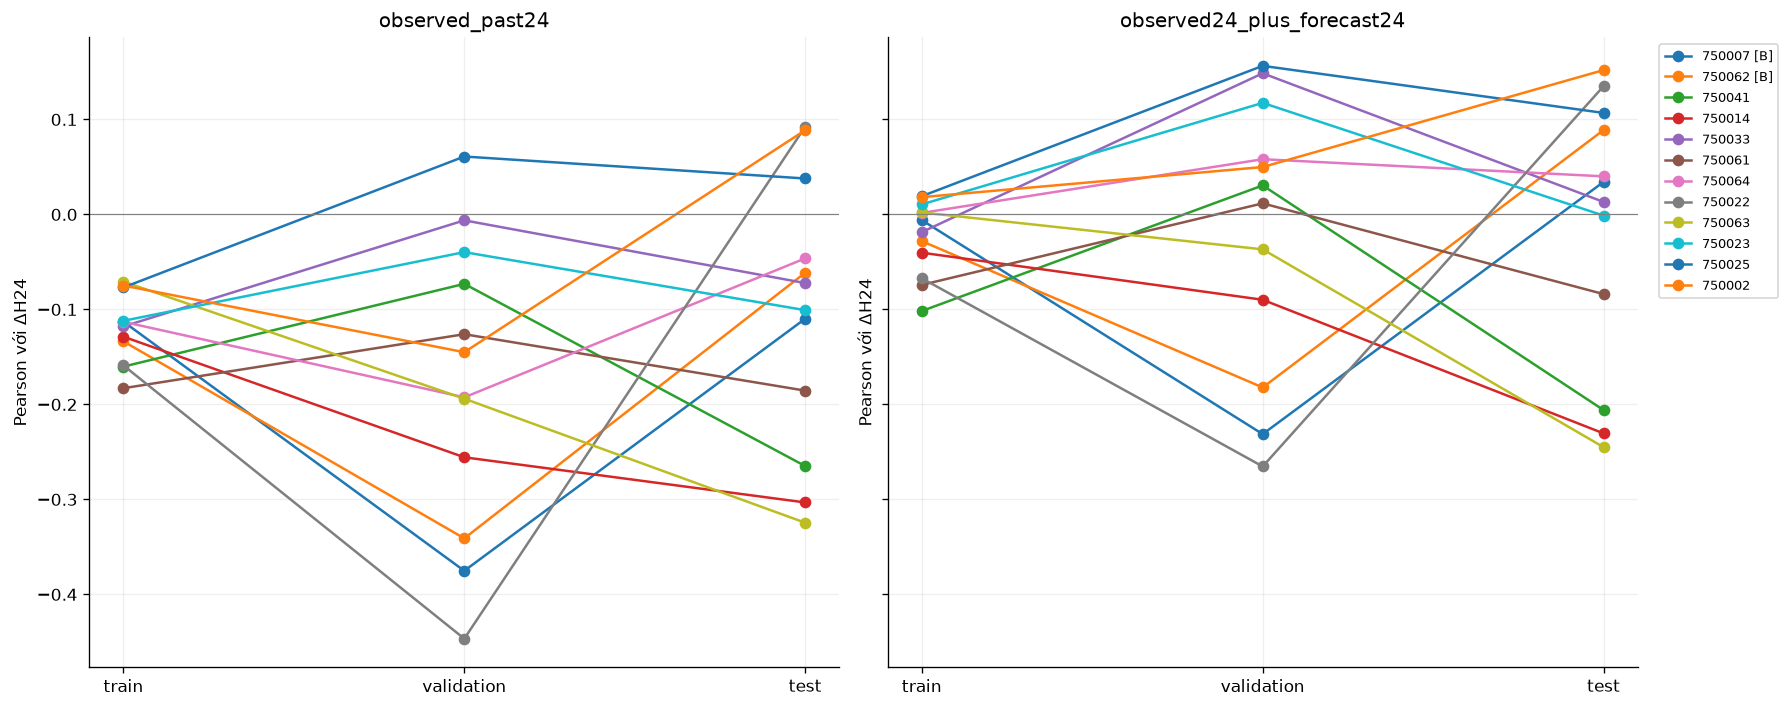

In [6]:
weather_rows=[]
for scope in scopes:
    frame=frames[scope]
    weather=frame[FORECAST_COLS].copy()
    for c in FORECAST_COLS:
        weather[c]=weather[c].where(frame[c+'_missing'].eq(0))
    weather['forecast_total_24h']=weather[FORECAST_COLS].sum(axis=1,min_count=4)
    for h in [12,24]:
        delta=frame[f'target_water_level_plus_{h*60}m']-frame.water_level_depth
        for c in weather:
            valid=weather[c].notna()&delta.notna()
            weather_rows.append(dict(scope=scope,horizon=h,feature=c,n=int(valid.sum()),
                pearson=corr(weather.loc[valid,c],delta[valid]),
                spearman=corr(weather.loc[valid,c],delta[valid],'spearman')))
weather_results=pd.DataFrame(weather_rows)
display(weather_results.round(3))

train_selection=common_tables['train'].head(6).station_id.tolist()
tracked_ids=list(dict.fromkeys([*sorted(MODEL_B),*spec['rain_station_ids'],*train_selection]))
tracked=results.loc[results.station_id.isin(tracked_ids)]
print('Các trạm được theo dõi: 6 trạm pool hiện tại + top 6 chọn trên train.')
display(tracked.pivot(index=['station_id','name','direction','horizon','predictor'],columns='scope',values='pearson').round(3))
fig,axes=plt.subplots(1,2,figsize=(15,6),sharey=True)
for ax,predictor in zip(axes,['observed_past24','observed24_plus_forecast24']):
    for sid in tracked_ids:
        group=results.loc[results.station_id.eq(sid)&results.horizon.eq(24)&results.predictor.eq(predictor)].set_index('scope').reindex(['train','val','test'])
        ax.plot([0,1,2],group.pearson,marker='o',label=sid+(' [B]' if sid in MODEL_B else ''))
    ax.set_xticks([0,1,2],['train','validation','test'])
    ax.axhline(0,color='grey',linewidth=.7)
    ax.set(title=predictor,ylabel='Pearson với ΔH24')
    ax.grid(alpha=.2)
axes[-1].legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
fig.tight_layout()
show()

## 5. Scatter trên train và bảng kết luận
Scatter dùng top 4 train theo correlation tổng hai phần, trên cùng cohort train. Các trạm là đại diện mưa, chưa được gán quan hệ dòng chảy tới Dã Viên. Cộng quan trắc và forecast có thể làm correlation tăng hoặc giảm do sai số forecast, khác vị trí ô lưới và khác tỷ trọng; không coi phép cộng là tối ưu.


Cột past_r: chỉ mưa (t−48h,t−24h]. Cột combined_r: thêm forecast (t−24h,t] lấy tại t−24h.
Không dùng mưa quan trắc trong 24h ngay trước target t. Không lấy forecast được tạo sau input s.
All/test là khám phá; đây không phải bằng chứng một tổ hợp trạm sẽ làm model tốt hơn.


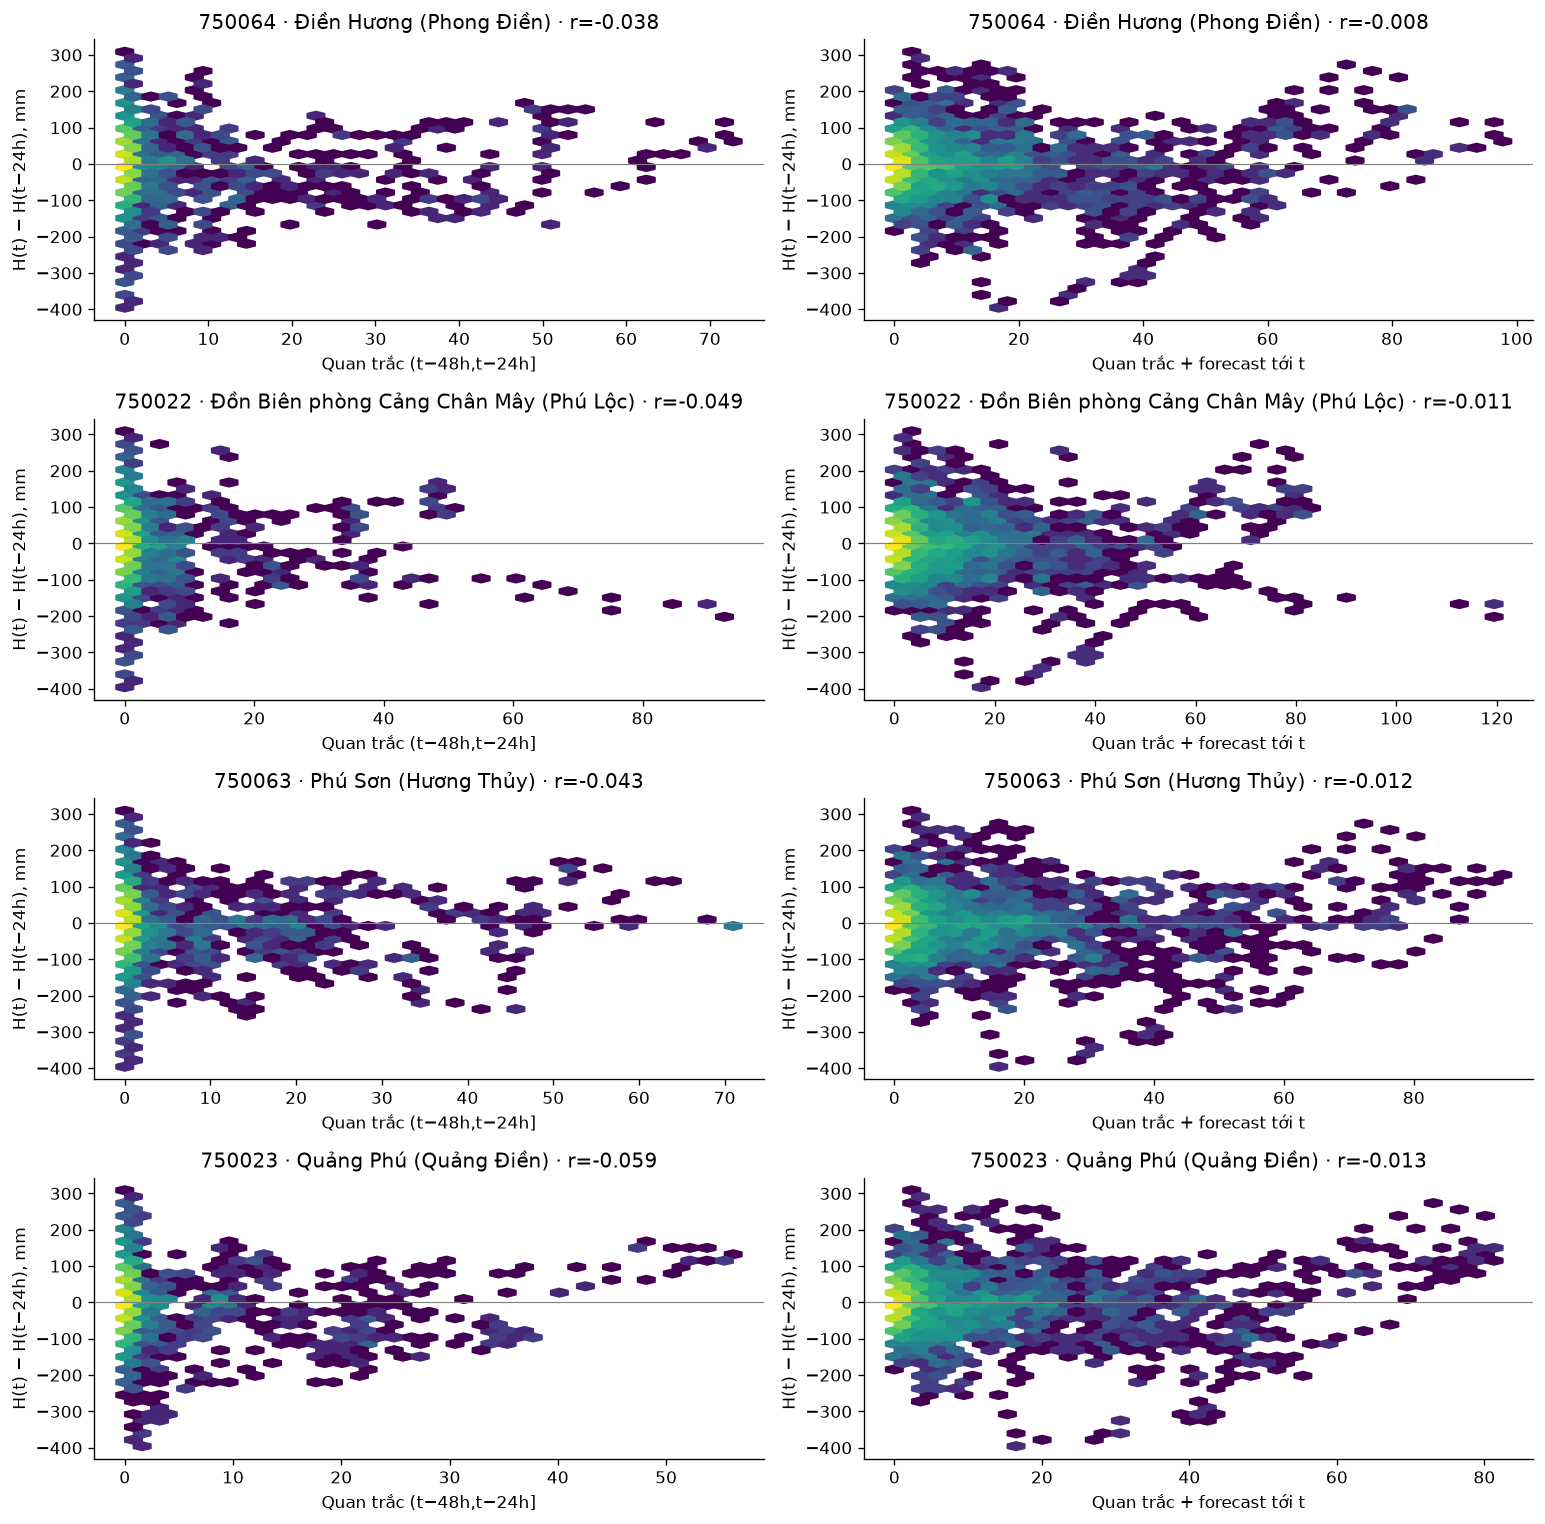

### Top 10 all: tổng mưa quan trắc 24h + forecast 24h, cùng cohort

,station_id,name,direction,model_B,n,past_r,forecast_r,combined_r,combined_spearman,past_rank,combined_rank
40,750045,Đan Điền (Đập Cửa Lác),Bắc,False,4519,-0.032,0.153,0.083,0.003,2.0,1.0
27,750025,Thị trấn Phong Điền (Phong Điền),Tây,False,4519,-0.009,0.153,0.078,0.023,1.0,2.0
13,750006,Hương Nguyên (A Lưới),Nam,False,4519,-0.087,0.153,0.076,0.001,13.0,3.0
37,750040,Hương Chữ (Hương Trà),Tây,False,4519,-0.058,0.153,0.064,0.020,6.0,4.0
33,750032,Trạm bơm Quảng Thành (Quảng Điền),Bắc,False,4519,-0.091,0.153,0.058,0.014,14.0,5.0
25,750023,Quảng Phú (Quảng Điền),Tây,False,4519,-0.074,0.153,0.051,0.015,9.0,6.0
34,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,False,4519,-0.082,0.153,0.051,0.016,12.0,7.0
5,677851,TT Sịa (Quảng Điền),Bắc,False,4519,-0.096,0.153,0.045,0.013,15.0,8.0
7,681524,Hồ Thọ Sơn (Hương Trà),Tây,False,4519,-0.062,0.153,0.041,0.009,7.0,9.0
23,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đông,False,4519,-0.052,0.153,0.039,0.006,5.0,10.0


### Top 10 train: tổng mưa quan trắc 24h + forecast 24h, cùng cohort

,station_id,name,direction,model_B,n,past_r,forecast_r,combined_r,combined_spearman,past_rank,combined_rank
47,750064,Điền Hương (Phong Điền),Bắc,False,3879,-0.038,0.019,-0.008,-0.028,1.0,1.0
24,750022,Đồn Biên phòng Cảng Chân Mây (Phú Lộc),Đông,False,3879,-0.049,0.019,-0.011,-0.025,4.0,2.0
46,750063,Phú Sơn (Hương Thủy),Nam,False,3879,-0.043,0.019,-0.012,-0.033,2.0,3.0
25,750023,Quảng Phú (Quảng Điền),Tây,False,3879,-0.059,0.019,-0.013,-0.030,7.0,4.0
27,750025,Thị trấn Phong Điền (Phong Điền),Tây,False,3879,-0.053,0.019,-0.014,-0.023,6.0,5.0
10,750002,Hồ Mỹ Xuyên (Phong Điền),Tây,False,3879,-0.050,0.019,-0.016,-0.024,5.0,6.0
9,750001,TT Phú Đa (Phú Vang),Đông,False,3879,-0.065,0.019,-0.018,-0.026,8.0,7.0
17,750010,Giang Hải (Phú Lộc),Đông,False,3879,-0.047,0.019,-0.019,-0.029,3.0,8.0
23,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đông,False,3879,-0.074,0.019,-0.023,-0.043,9.0,9.0
19,750012,"Đập, Thủy điện Thượng Nhật (Phú Lộc)",Nam,False,3879,-0.095,0.019,-0.027,-0.007,17.0,10.0


In [7]:
chosen=common_tables['train'].head(4)
if len(chosen):
    frame=frames['train']
    valid=common_masks['train']
    target=frame.target_water_level_plus_1440m-frame.water_level_depth
    forecast=frame[FORECAST_COLS].sum(axis=1,min_count=4)
    fig,axes=plt.subplots(len(chosen),2,figsize=(13,3.2*len(chosen)),squeeze=False)
    for row_axes,(_,station) in zip(axes,chosen.iterrows()):
        observed=past['train'][station.station_id]
        for ax,(label,values) in zip(row_axes,[('Quan trắc (t−48h,t−24h]',observed),('Quan trắc + forecast tới t',observed+forecast)]):
            ax.hexbin(values[valid],target[valid],gridsize=35,mincnt=1,bins='log',cmap='viridis')
            ax.axhline(0,color='grey',linewidth=.7)
            ax.set_title(f"{station.station_id} · {station['name']} · r={corr(values[valid],target[valid]):.3f}")
            ax.set_xlabel(label)
            ax.set_ylabel('H(t) − H(t−24h), mm')
    fig.tight_layout()
    show()

for scope in ['all','train']:
    table=common_tables[scope]
    display(Markdown(f'### Top 10 {scope}: tổng mưa quan trắc 24h + forecast 24h, cùng cohort'))
    display(table.head(10).round(3))
print('Cột past_r: chỉ mưa (t−48h,t−24h]. Cột combined_r: thêm forecast (t−24h,t] lấy tại t−24h.')
print('Không dùng mưa quan trắc trong 24h ngay trước target t. Không lấy forecast được tạo sau input s.')
print('All/test là khám phá; đây không phải bằng chứng một tổ hợp trạm sẽ làm model tốt hơn.')

## 6. Đối chiếu đúng sáu trạm đang thử và nhãn mực nước H(t)
Bảng riêng này chỉ giao dữ liệu **6 trạm trong dataset pool**, tránh việc giao 55 trạm làm mất quá nhiều sự kiện. Hiển thị số anchor còn lại. H(t) là nhãn mực nước tuyệt đối của dataset; ΔH24 là phần thay đổi so với input, phù hợp để xem tín hiệu cho mô hình residual. Hai loại correlation trả lời hai câu hỏi khác nhau, không thay thế nhau.

Trong các bảng toàn mạng phía trên, tập cặp riêng từng trạm giữ được nhiều mẫu hơn; cohort giao toàn mạng có thể mất các đợt quan trọng. Không coi thứ hạng trên cohort giao là kết luận chắc chắn cho toàn bộ dataset.


In [8]:
pool_rows=[]
for scope in scopes:
    frame=frames[scope]
    ids=spec['rain_station_ids']
    forecast=frame[FORECAST_COLS].sum(axis=1,min_count=4)
    flags=frame[[c+'_missing' for c in FORECAST_COLS]].eq(0).all(axis=1)
    valid=past[scope][ids].notna().all(axis=1)&forecast.notna()&flags
    level=frame.target_water_level_plus_1440m
    delta=level-frame.water_level_depth
    for sid in ids:
        observed=past[scope][sid]
        pool_rows.append(dict(scope=scope,station_id=sid,name=catalog.loc[sid,'name'],
            direction=catalog.loc[sid,'direction'],n=int(valid.sum()),cohort_coverage=float(valid.mean()),
            past_vs_delta=corr(observed[valid],delta[valid]),
            forecast_vs_delta=corr(forecast[valid],delta[valid]),
            sum_vs_delta=corr((observed+forecast)[valid],delta[valid]),
            past_vs_level=corr(observed[valid],level[valid]),
            forecast_vs_level=corr(forecast[valid],level[valid]),
            sum_vs_level=corr((observed+forecast)[valid],level[valid])))
pool_results=pd.DataFrame(pool_rows)
for scope in ['all','train','val','test']:
    display(Markdown(f'### {scope}: 6 trạm pool, cùng tập cặp; đích H(t) và ΔH24'))
    display(pool_results.loc[pool_results.scope.eq(scope)].round(3))

print('Toàn mạng, correlation với nhãn tuyệt đối H(t), từng trạm dùng cặp hợp lệ riêng:')
display(results.loc[results.horizon.eq(24)&results.scope.isin(['all','train'])].pivot(
    index=['station_id','name','direction'],columns=['scope','predictor'],values='level_r').round(3))

Toàn mạng, correlation với nhãn tuyệt đối H(t), từng trạm dùng cặp hợp lệ riêng:


### all: 6 trạm pool, cùng tập cặp; đích H(t) và ΔH24

,scope,station_id,name,direction,n,cohort_coverage,past_vs_delta,forecast_vs_delta,sum_vs_delta,past_vs_level,forecast_vs_level,sum_vs_level
0,all,750062,Hồng Thái (A Lưới),Tây,7566,0.986,-0.169,0.139,-0.064,0.175,0.259,0.243
1,all,750007,Nhâm (A Lưới),Tây,7566,0.986,-0.175,0.139,-0.081,0.137,0.259,0.211
2,all,750041,Bạch Mã,Đông,7566,0.986,-0.138,0.139,-0.067,0.283,0.259,0.313
3,all,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,7566,0.986,-0.165,0.139,-0.070,0.207,0.259,0.268
4,all,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,7566,0.986,-0.062,0.139,0.039,0.263,0.259,0.319
5,all,750061,Thủy điện Bình Điền (Hương Trà),Nam,7566,0.986,-0.134,0.139,-0.031,0.253,0.259,0.297


### train: 6 trạm pool, cùng tập cặp; đích H(t) và ΔH24

,scope,station_id,name,direction,n,cohort_coverage,past_vs_delta,forecast_vs_delta,sum_vs_delta,past_vs_level,forecast_vs_level,sum_vs_level
6,train,750062,Hồng Thái (A Lưới),Tây,6071,0.996,-0.134,0.079,-0.028,0.121,0.17,0.185
7,train,750007,Nhâm (A Lưới),Tây,6071,0.996,-0.114,0.079,-0.007,0.049,0.17,0.152
8,train,750041,Bạch Mã,Đông,6071,0.996,-0.160,0.079,-0.100,0.157,0.17,0.184
9,train,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,6071,0.996,-0.129,0.079,-0.041,0.158,0.17,0.195
10,train,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,6071,0.996,-0.119,0.079,-0.020,0.168,0.17,0.208
11,train,750061,Thủy điện Bình Điền (Hương Trà),Nam,6071,0.996,-0.183,0.079,-0.074,0.187,0.17,0.214


### val: 6 trạm pool, cùng tập cặp; đích H(t) và ΔH24

,scope,station_id,name,direction,n,cohort_coverage,past_vs_delta,forecast_vs_delta,sum_vs_delta,past_vs_level,forecast_vs_level,sum_vs_level
12,val,750062,Hồng Thái (A Lưới),Tây,903,0.917,-0.343,0.227,-0.182,0.532,0.615,0.636
13,val,750007,Nhâm (A Lưới),Tây,903,0.917,-0.378,0.227,-0.232,0.508,0.615,0.606
14,val,750041,Bạch Mã,Đông,903,0.917,-0.072,0.227,0.034,0.695,0.615,0.739
15,val,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,903,0.917,-0.256,0.227,-0.090,0.491,0.615,0.632
16,val,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,903,0.917,-0.005,0.227,0.153,0.596,0.615,0.697
17,val,750061,Thủy điện Bình Điền (Hương Trà),Nam,903,0.917,-0.125,0.227,0.015,0.680,0.615,0.736


### test: 6 trạm pool, cùng tập cặp; đích H(t) và ΔH24

,scope,station_id,name,direction,n,cohort_coverage,past_vs_delta,forecast_vs_delta,sum_vs_delta,past_vs_level,forecast_vs_level,sum_vs_level
18,test,750062,Hồng Thái (A Lưới),Tây,592,1.0,-0.061,0.408,0.089,0.219,0.609,0.408
19,test,750007,Nhâm (A Lưới),Tây,592,1.0,-0.110,0.408,0.034,0.152,0.609,0.338
20,test,750041,Bạch Mã,Đông,592,1.0,-0.265,0.408,-0.206,0.519,0.609,0.566
21,test,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,592,1.0,-0.303,0.408,-0.230,0.422,0.609,0.486
22,test,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,592,1.0,-0.072,0.408,0.013,0.581,0.609,0.630
23,test,750061,Thủy điện Bình Điền (Hương Trà),Nam,592,1.0,-0.185,0.408,-0.084,0.286,0.609,0.397


scope                                                                    all  \
predictor                                                    observed_past24   
station_id name                                    direction                   
14690      Hồ chứa nước Thủy Yên                   Đông                0.342   
14696      Hồ chứa nước Khe Ngang                  Tây                 0.255   
14699      Hồ chứa nước Truồi                      Đông                0.266   
228005     Cảng Chân Mây                           Đông                0.272   
228006     VPTT PCTTHUE                            Đông                0.286   
567011     Quan Tượng Đài (Phú Xuân)               Bắc                 0.264   
677493     TT Khe Tre (Phú Lộc)                    Nam                 0.334   
677851     TT Sịa (Quảng Điền)                     Bắc                 0.286   
678628     Tà Lương (A Lưới)                       Tây                 0.241   
681524     Hồ Thọ Sơn (Hương Trà)                  Tây                 0.271   
682816     Hồ Hòa Mỹ (Phong Điền)                  Tây                 0.243   
750001     TT Phú Đa (Phú Vang)                    Đông                0.252   
750002     Hồ Mỹ Xuyên (Phong Điền)                Tây                 0.243   
750003     Thị trấn A Lưới (A Lưới)                Tây                 0.177   
750005     Hồng Vân (A Lưới)                       Tây                 0.180   
750006     Hương Nguyên (A Lưới)                   Nam                 0.261   
750007     Nhâm (A Lưới)                           Tây                 0.138   
750008     A Đớt (A Lưới)                          Nam                 0.227   
750009     Lộc Tiến (Phú Lộc)                      Đông                0.331   
750010     Giang Hải (Phú Lộc)                     Đông                0.261   
750011     Hồ A Lá (A Lưới)                        Tây                 0.179   
750012     Đập, Thủy điện Thượng Nhật (Phú Lộc)    Nam                 0.326   
750013     Lưu vực Thủy điện Thượng Nhật (Phú Lộc) Nam                 0.153   
750014     Hồ chứa nước Phú Bài (Hương Thủy)       Đông                0.207   
750015     Hồ Tà Rinh (Phú Lộc)                    Nam                 0.328   
750016     Trạm bơm Sơn Bổn                        Đông                0.213   
750021     Đồn Biên phòng Lăng Cô (Phú Lộc)        Đông                0.332   
750022     Đồn Biên phòng Cảng Chân Mây (Phú Lộc)  Đông                0.266   
750023     Quảng Phú (Quảng Điền)                  Tây                 0.255   
750024     An Tây (Thuận Hóa)                      Nam                 0.266   
750025     Thị trấn Phong Điền (Phong Điền)        Tây                 0.298   
750026     Bình Tiến (Hương Trà)                   Tây                 0.252   
750027     Thủy Thanh (Hương Thủy)                 Đông                0.255   
750028     Hương Sơn (Phú Lộc)                     Nam                 0.298   
750029     Thượng Quảng (Phú Lộc)                  Nam                 0.321   
750030     Vườn Quốc gia Bạch Mã (Phú Lộc)         Đông                0.368   
750032     Trạm bơm Quảng Thành (Quảng Điền)       Bắc                 0.269   
750033     VP QLKTCTTL TP Huế (TP Huế)             Bắc                 0.264   
750034     Trạm bơm Vinh Hà (Phú Vang)             Đông                0.284   
750035     Cảng Tư Hiền                            Đông                0.272   
750040     Hương Chữ (Hương Trà)                   Tây                 0.271   
750041     Bạch Mã                                 Đông                0.284   
750042     Trạm kiểm lâm Khe Mỏ Rang               Nam                 0.300   
750045     Đan Điền (Đập Cửa Lác)                  Bắc                 0.279   
750046     Vỹ Dạ                                   Đông                0.252   
750047     Lộc An                                  Đông                0.261   
750059     Cảng Thuận An                           Bắc                 0.213   


## 7. Kiểm tra căn thời gian và tính nhất quán
Các kiểm tra dưới đây xác nhận cohort giống dataset, nhãn khớp quan trắc đúng timestamp, nguồn B giữ nguyên, forecast thỏa giả định độ trễ công bố, và các predictor trong bảng so sánh chính dùng cùng tập mẫu.


In [9]:
assert sum(len(frames[s]) for s in ['train','val','test'])==len(frames['all'])
for scope in scopes:
    frame=frames[scope]
    for sid in spec['rain_station_ids']:
        np.testing.assert_allclose(past[scope][sid],frame[f'rain_{sid}_sum_24h'],equal_nan=True)
    target_time=frame.index+pd.Timedelta(hours=24)
    assert (target_time-pd.Timedelta(hours=48)==frame.index-pd.Timedelta(hours=24)).all()
    assert (target_time-pd.Timedelta(hours=24)==frame.index).all()
    forecast_age=(frame.index-provenance.reindex(frame.index).initialized_at).dt.total_seconds()/3600
    np.testing.assert_allclose(forecast_age,frame.weather_forecast_age_hours)
    if len(common_tables[scope]):
        assert common_tables[scope].n.nunique()==1
        assert common_tables[scope].forecast_r.dropna().nunique()<=1
    for sid in catalog.index:
        same_rows=results.loc[results.scope.eq(scope)&results.station_id.eq(sid)&results.horizon.eq(24)]
        assert same_rows.n.nunique()==1
print('PASS: alignment s=t−24h; observation t−48→t−24; forecast t−24→t; cohort/labels/provenance nhất quán.')

PASS: alignment s=t−24h; observation t−48→t−24; forecast t−24→t; cohort/labels/provenance nhất quán.
